In [1]:
from google.colab import files
uploaded=files.upload()

Saving online_retail_II.xlsx to online_retail_II.xlsx


In [6]:

import pandas as pd

file_name = next(iter(uploaded))

sheets = pd.read_excel(file_name, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

df.head()


Dataset Shape: (1067371, 8)

Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows without Customer ID or InvoiceDate
df = df.dropna(subset=["Customer ID", "InvoiceDate"]).copy()

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["InvoiceDate"])

# Remove cancelled invoices
df = df[
    ~df["Invoice"].astype(str).str.startswith("C")
].copy()

# Keep valid purchases only
df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

# Standardize Customer ID
df["Customer ID"] = df["Customer ID"].astype(int)

print("\nDataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df[["Customer ID", "InvoiceDate"]].isnull().sum())

df.head()


Missing values before cleaning:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Dataset shape after cleaning: (805549, 8)

Missing values after cleaning:
Customer ID    0
InvoiceDate    0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [8]:

# Extract the month of each purchase
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")

# Find each customer's first purchase month
df["CohortMonth"] = (
    df.groupby("Customer ID")["InvoiceMonth"]
      .transform("min")
)

# Calculate months since the first purchase
df["CohortIndex"] = (
    (df["InvoiceMonth"].dt.year - df["CohortMonth"].dt.year) * 12
    + (df["InvoiceMonth"].dt.month - df["CohortMonth"].dt.month)
    + 1
)

print("Cohort columns created successfully!")
df[["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex"]].head()


Cohort columns created successfully!


,Customer ID,InvoiceMonth,CohortMonth,CohortIndex
0,13085,2009-12,2009-12,1
1,13085,2009-12,2009-12,1
2,13085,2009-12,2009-12,1
3,13085,2009-12,2009-12,1
4,13085,2009-12,2009-12,1


In [9]:

# Count unique customers in each cohort and month
cohort_data = (
    df.groupby(["CohortMonth", "CohortIndex"])["Customer ID"]
      .nunique()
      .reset_index()
)

# Create the cohort table
cohort_counts = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="Customer ID"
)

# Calculate retention percentage
cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.div(
    cohort_sizes, axis=0
) * 100

# Display the retention table
retention = retention.round(2)

print("Cohort Retention Table (%)")
display(retention)


Cohort Retention Table (%)


CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,35.29,33.40,42.51,38.01,35.92,37.70,34.24,33.61,36.23,...,30.26,26.28,30.26,28.27,25.97,25.55,31.52,30.47,40.73,19.69
2010-01,100.0,20.63,31.07,30.55,26.37,30.03,25.85,22.98,27.94,31.85,...,15.14,23.50,19.84,18.54,19.58,24.28,19.32,24.54,5.74,NaN
2010-02,100.0,23.80,22.46,29.14,24.60,20.05,19.25,28.61,25.40,27.54,...,20.05,16.04,16.31,14.44,22.99,22.99,16.31,5.88,NaN,NaN
2010-03,100.0,18.96,23.02,24.15,23.25,20.32,24.60,30.25,27.54,10.84,...,16.93,17.38,15.58,17.61,20.09,21.22,7.90,NaN,NaN,NaN
2010-04,100.0,19.39,19.39,16.33,18.37,22.45,27.55,26.19,10.54,10.88,...,15.65,13.95,14.97,18.03,22.45,5.78,NaN,NaN,NaN,NaN
2010-05,100.0,15.75,16.93,17.32,17.72,25.59,21.26,12.60,5.91,8.27,...,12.60,13.78,16.54,15.35,4.72,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.41,18.89,20.37,22.96,28.52,12.59,8.89,8.15,11.85,...,12.22,13.33,20.37,5.19,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,11.29,...,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.37,29.63,32.10,17.28,11.73,9.88,12.35,13.58,12.96,...,19.75,6.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


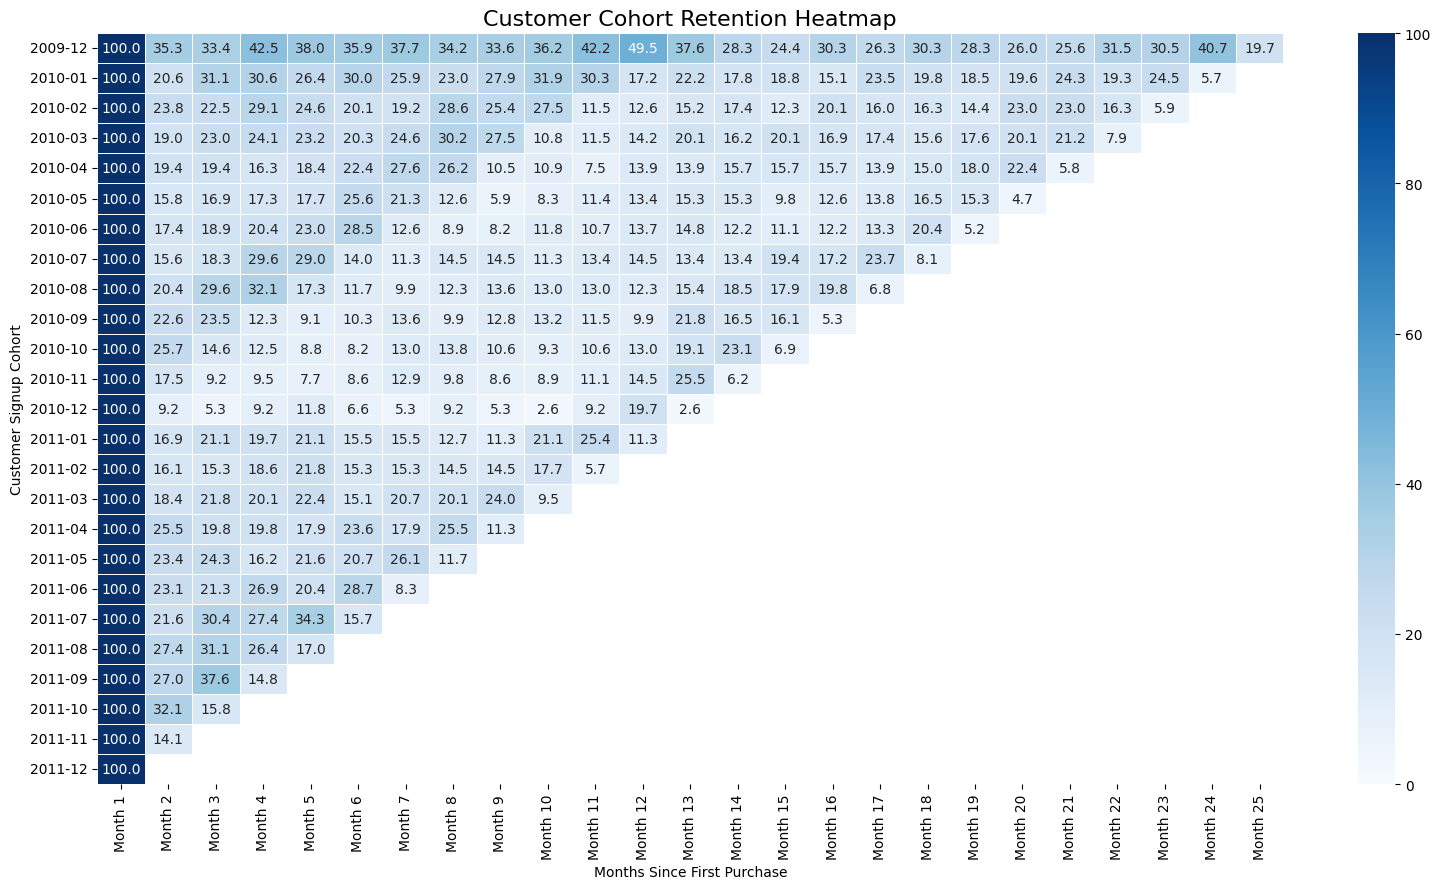

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Format cohort labels
retention.index = retention.index.astype(str)
retention.columns = [
    f"Month {int(col)}" for col in retention.columns
]

plt.figure(figsize=(16, 9))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title("Customer Cohort Retention Heatmap", fontsize=16)
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Signup Cohort")
plt.tight_layout()

plt.savefig("Cohort_Retention_Heatmap.png", dpi=300)
plt.show()


In [11]:

# Save retention table
retention.to_csv("Cohort_Retention_Table.csv")

# Save customer counts
cohort_data.to_csv(
    "Cohort_Customer_Counts.csv",
    index=False
)

print("Both CSV files saved successfully!")


Both CSV files saved successfully!


In [12]:

from google.colab import files

files.download("Cohort_Retention_Table.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

files.download("Cohort_Customer_Counts.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

files.download("Cohort_Retention_Heatmap.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

# Average retention across cohorts
average_retention = retention.mean(axis=0)

print("Average Retention by Cohort Month:")
display(average_retention.round(2))

# Month 1 versus Month 2 retention
if retention.shape[1] >= 2:
    month2 = retention.iloc[:, 1].dropna()
    print(
        "\nAverage Month 2 Retention:",
        round(month2.mean(), 2), "%"
    )

# Best cohort for Month 2 retention
if retention.shape[1] >= 2:
    best_cohort = retention.iloc[:, 1].idxmax()
    best_value = retention.loc[best_cohort].iloc[1]

    print("\nBest Month 2 Cohort:", best_cohort)
    print("Month 2 Retention:", round(best_value, 2), "%")


Average Retention by Cohort Month:


,0
Month 1,100.00
Month 2,21.17
Month 3,21.92
Month 4,21.62
Month 5,20.54
Month 6,18.84
Month 7,17.82
Month 8,17.66
Month 9,15.62
Month 10,15.26



Average Month 2 Retention: 21.17 %

Best Month 2 Cohort: 2009-12
Month 2 Retention: 35.29 %


In [16]:

df.to_csv("Online_Retail_Cleaned.csv", index=False)

from google.colab import files
files.download("Online_Retail_Cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>